# Step 4a (option 2) — Fine-tune DocLayout-YOLO

Fine-tunes [DocLayout-YOLO](https://github.com/opendatalab/DocLayout-YOLO) on our
Labelbox-annotated pages, so it can detect Figure/Table regions on the other
~90 unannotated papers. This notebook calls straight into
`step04a_prepare_yolo_dataset.py` and `step04a_finetune_doclayout_yolo.py`
(same folder) rather than re-implementing their logic, so training progress,
plots, and metrics all render inline here as you run it.

**Folder layout this notebook expects:**
```
2026/
  My_code/
    step03_labelbox_export_to_dataset.py
    step04_detection/
      02_doclayout_yolo_finetune/   <- this notebook lives here
  Pre-Pages-2Annotate/               <- ndjson export + topic image folders
  Outputs/
```

## Before running the real thing

**Pretrained weights matter a lot here.** Our annotated set is small (10
papers, ~105 boxes across 4 classes) and spans many different journal
templates. Fine-tuning from a document-layout-pretrained checkpoint (not
training from scratch) is what makes that workable. Download the official
DocStructBench weights on a machine with normal internet access:

> https://huggingface.co/juliozhao/DocLayout-YOLO-DocStructBench

(grab the `.pt` file, e.g. `doclayout_yolo_docstructbench_imgsz1024.pt`) and
point `WEIGHTS` at its local path below. Leaving `WEIGHTS` as a bare
`.yaml` trains from a random initialization instead — only useful as a fast
smoke test of the pipeline, not for real detection accuracy.

**GPU strongly recommended.** The training cell uses 100 epochs, 1024-pixel
images, and batch size 8. Batch 32 exhausted MPS memory on the 48 GB M3 Max.
Device selection automatically uses CUDA, then Apple MPS (Mac GPU), then
CPU, depending on availability in PyTorch.


In [1]:
%matplotlib inline
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))
import step04a_prepare_yolo_dataset as prep
import step04a_finetune_doclayout_yolo as ft

# ── paths ──
NDJSON_PATH = Path("../../../Pre-Pages-2Annotate") / "Export  project - STEPS-Paper-Annotation - 9_12_2026.ndjson"
IMAGES_ROOT = Path("../../../Pre-Pages-2Annotate")          # searched recursively across topic folders
YOLO_DATASET = Path("./cleanup_check/yolo_dataset")                        # written by step 1 below

assert NDJSON_PATH.exists(), f"Export not found at {NDJSON_PATH.resolve()}"
assert IMAGES_ROOT.exists(), f"Images root not found at {IMAGES_ROOT.resolve()}"
print("Paths OK.")


Paths OK.


## Step 1 — Build the YOLO train/val split

Reuses step03's exact box-resolution logic (a `Figure_Mixed` composite's
outer box is kept, its nested Plot/Diagram sub-boxes are excluded -- see
step03's docstring for why). Splits by **paper**, not by page, so
validation actually measures generalization to a paper the model has never
seen, which is the real test for the other ~90 papers. Background
(no-graphics) pages are included as negative examples.


In [2]:
stats = prep.prepare_dataset(
    ndjson_path=NDJSON_PATH,
    images_root=IMAGES_ROOT,
    output_root=YOLO_DATASET,
    val_fraction=0.15,
)


──────────────────────────────────────────────────────
Papers total: 10  (val: 2)
Train: 94 pages, 86 boxes, 33 background
Val:   30 pages, 19 boxes, 13 background

Classes (4): ['Table', 'Plot', 'Diagram', 'Figure_Mixed']

Val papers (held out entirely, to test generalization to unseen papers):
    - Carbon-and-nutrient-recovery-in-the-cultivation-of-Chlorell_2018_Journal-of-
    - Feasibility-of-alternative-sewage-sludge-treatment-meth_2020_Journal-of-Clea

[Warning] 11 background page(s) are BLANK SUBMISSIONS -- no objects were drawn AND the 'No Graphics' checkbox wasn't checked, so it's unconfirmed whether these pages truly have nothing to detect (vs. an annotator who skipped them). They're currently included as negative training examples. Worth a quick look before trusting them as ground truth:
    - Biomethane-production-enhancement-from-waste-activated-slud_2024_Journal-of-_page_0010.png
    - Biosorption-of-copper-ions-through-microalgae-from-pigge_2021_Journal-of-Cle_page_0001

## Step 2 — Fine-tune

`WEIGHTS` below points to the downloaded DocStructBench checkpoint beside
this notebook. The local training helper includes a compatibility fix for
DocLayout-YOLO 0.0.4: final checkpoint validation keeps the shared convolution
layers unfused. To make a short smoke test, temporarily set `EPOCHS = 1`.

**Reading the progress output:**

- `CUDA_mem` is a CUDA-only counter; on Mac, use the separately printed MPS memory reading.
- `box_om`/`box_oo` measure box errors and `cls_om`/`cls_oo` measure class errors in the two training branches; lower is better.
- DFL is disabled in this model, so its zero values are expected.
- This package does not calculate validation losses: their zero placeholders do not mean perfect predictions. Use precision, recall, and mAP to judge validation performance.

Restart the kernel after updating packages or helpers to activate the cleanup.


In [3]:
DEVICE = ft.select_device()  # CUDA -> Apple MPS -> CPU
print(f"Training, validation, and prediction device: {DEVICE}")

WEIGHTS = "./doclayout_yolo_docstructbench_imgsz1024.pt"
assert Path(WEIGHTS).is_file(), f"Checkpoint not found: {WEIGHTS}"
EPOCHS = 1  # smoke test only
IMGSZ   = 1024                # <-- DocStructBench was trained at 1024; use that for the real run
BATCH   = 8                  # batch 32 exhausted MPS memory at 1024

model, metrics = ft.finetune(
    data=str(stats["data_yaml"]),
    weights=WEIGHTS,
    epochs=EPOCHS,
    imgsz=IMGSZ,
    batch=BATCH,
    device=DEVICE,
    project="./cleanup_check/runs",
    name="doclayout_smoke",
)


Training, validation, and prediction device: mps
Backend:  doclayout_yolo
Weights:  ./doclayout_yolo_docstructbench_imgsz1024.pt
Device:   mps


Ultralytics YOLOv0.0.4 🚀 Python-3.11.12 torch-2.9.1 MPS (Apple M3 Max)


engine/trainer: task=detect, mode=train, model=./doclayout_yolo_docstructbench_imgsz1024.pt, data=/Users/md_halim_mondol/Desktop/STEPS-LLM/2026/My_code/step04_detection/02_doclayout_yolo_finetune/cleanup_check/yolo_dataset/data.yaml, epochs=1, time=None, patience=20, batch=8, imgsz=1024, save=True, save_period=10, val_period=1, cache=False, device=mps, workers=8, project=./cleanup_check/runs, name=doclayout_smoke, exist_ok=True, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=False, classes=None, retina_masks=False, embed=None, show=False, save_frames=False

Overriding model.yaml nc=10 with nc=4



                   from  n    params  module                                       arguments                     


  0                  -1  1      1392  doclayout_yolo.nn.modules.conv.Conv          [3, 48, 3, 2]                 


... (89 outputs left out)

30
                   all         30         19          0          0          0          0


Speed: 2.1ms preprocess, 70.7ms inference, 2.9ms postprocess per image


Results saved to cleanup_check/runs/doclayout_smoke



──────────────────────────────────────────────────────
mAP50:    0.0000
mAP50-95: 0.0000

Best weights saved under: ./cleanup_check/runs/doclayout_smoke/weights/best.pt


## Step 3 — Look at the results

Ultralytics writes several diagnostic plots per run (loss curves, PR curve,
confusion matrix, a grid of labeled training batches). Displaying them
inline here beats digging through the `runs/` folder by hand.


Run directory: cleanup_check/runs/doclayout_smoke


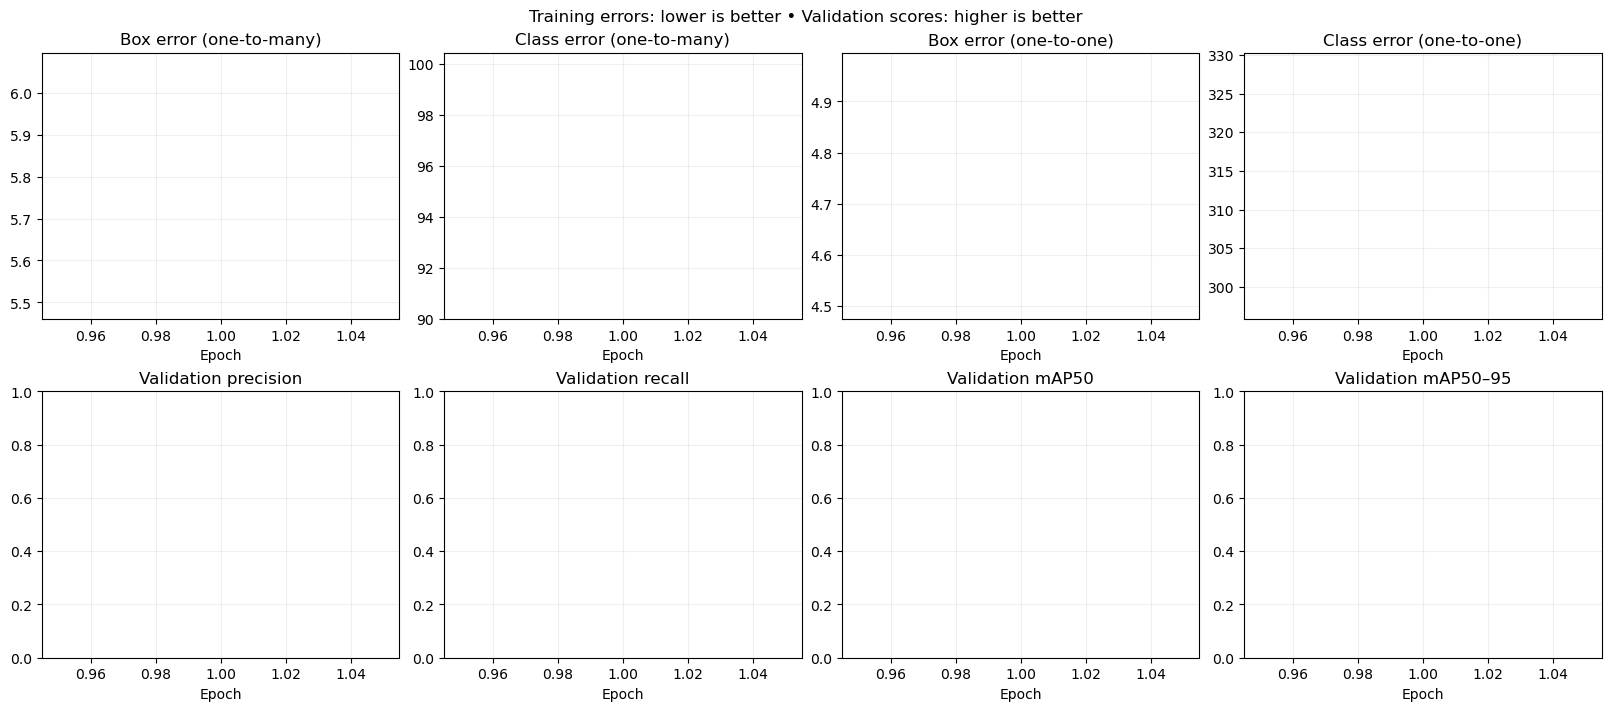

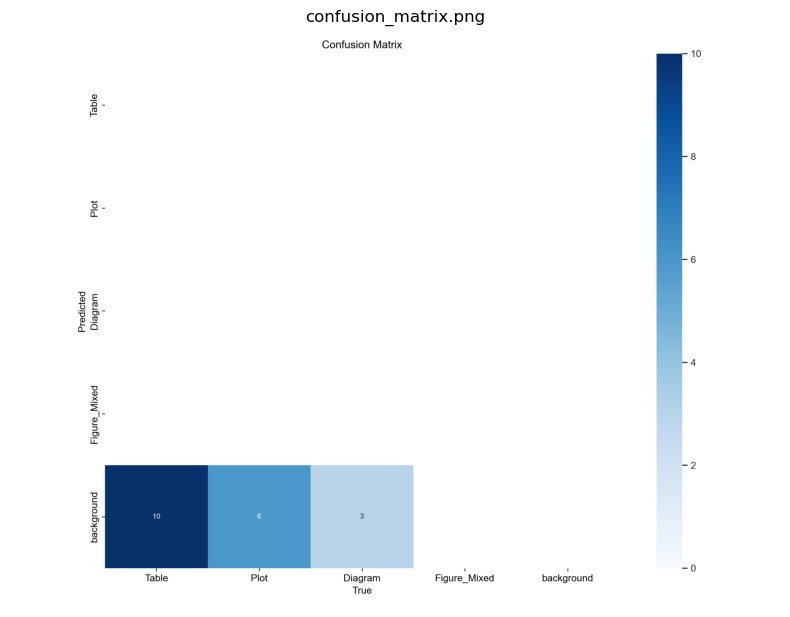

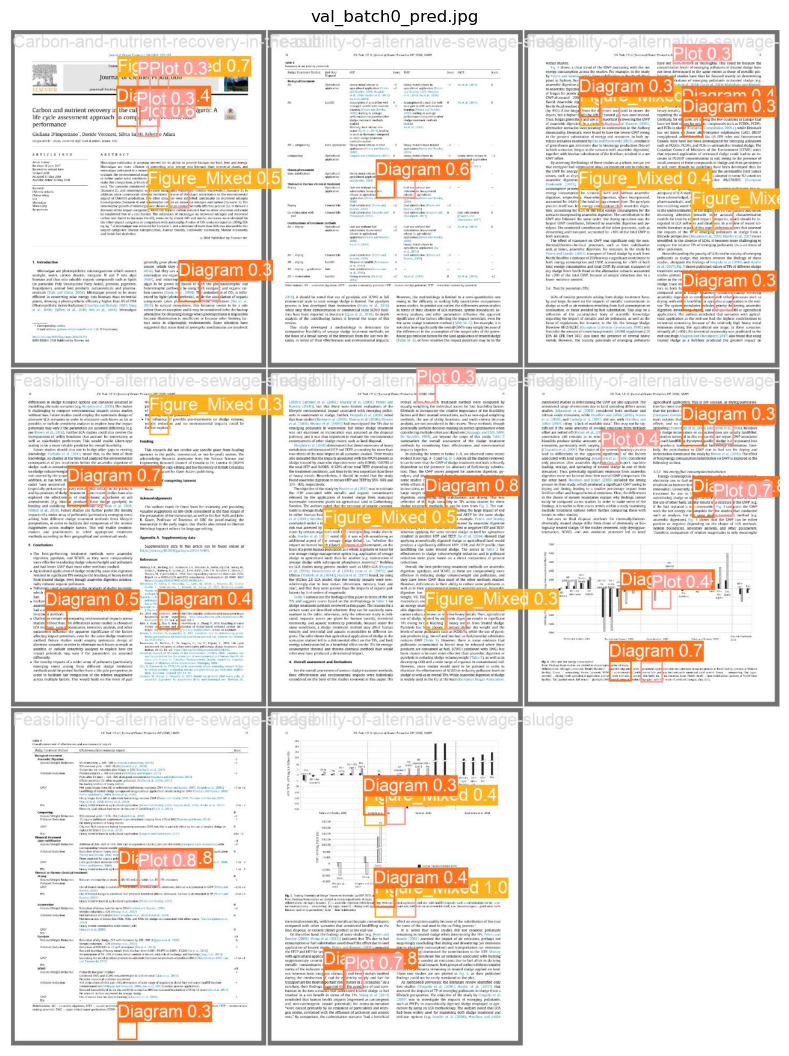

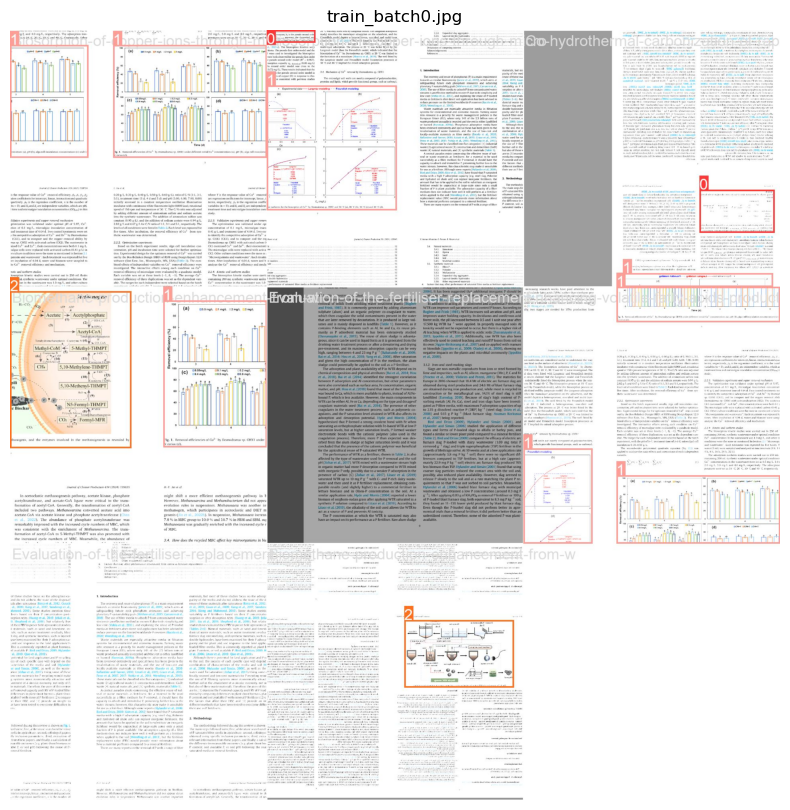

In [4]:
from PIL import Image
import matplotlib.pyplot as plt

run_dir = Path(model.trainer.save_dir)
print(f"Run directory: {run_dir}")

from doclayout_compat import plot_training_progress

# Show only measured losses/scores; omit disabled DFL and uncomputed val losses.
progress_figure = plot_training_progress(run_dir / "results.csv")
plt.show()

for fname in ["confusion_matrix.png", "val_batch0_pred.jpg", "train_batch0.jpg"]:
    fpath = run_dir / fname
    if fpath.exists():
        img = Image.open(fpath)
        plt.figure(figsize=(10, 10 * img.size[1] / img.size[0]))
        plt.imshow(img)
        plt.axis("off")
        plt.title(fname)
        plt.show()
    else:
        print(f"(not found: {fname})")


## Step 4 — Try the fine-tuned model on a held-out val page

A quick visual sanity check: run the just-trained model on a val-split page
it never saw during training, and see where it draws boxes.


image 1/1 /Users/md_halim_mondol/Desktop/STEPS-LLM/2026/My_code/step04_detection/02_doclayout_yolo_finetune/cleanup_check/yolo_dataset/images/val/Carbon-and-nutrient-recovery-in-the-cultivation-of-Chlorell_2018_Journal-of-_page_0005.png: 1024x768 3 Plots, 2 Diagrams, 735.2ms


Speed: 43.0ms preprocess, 735.2ms inference, 361.6ms postprocess per image at shape (1, 3, 1024, 768)


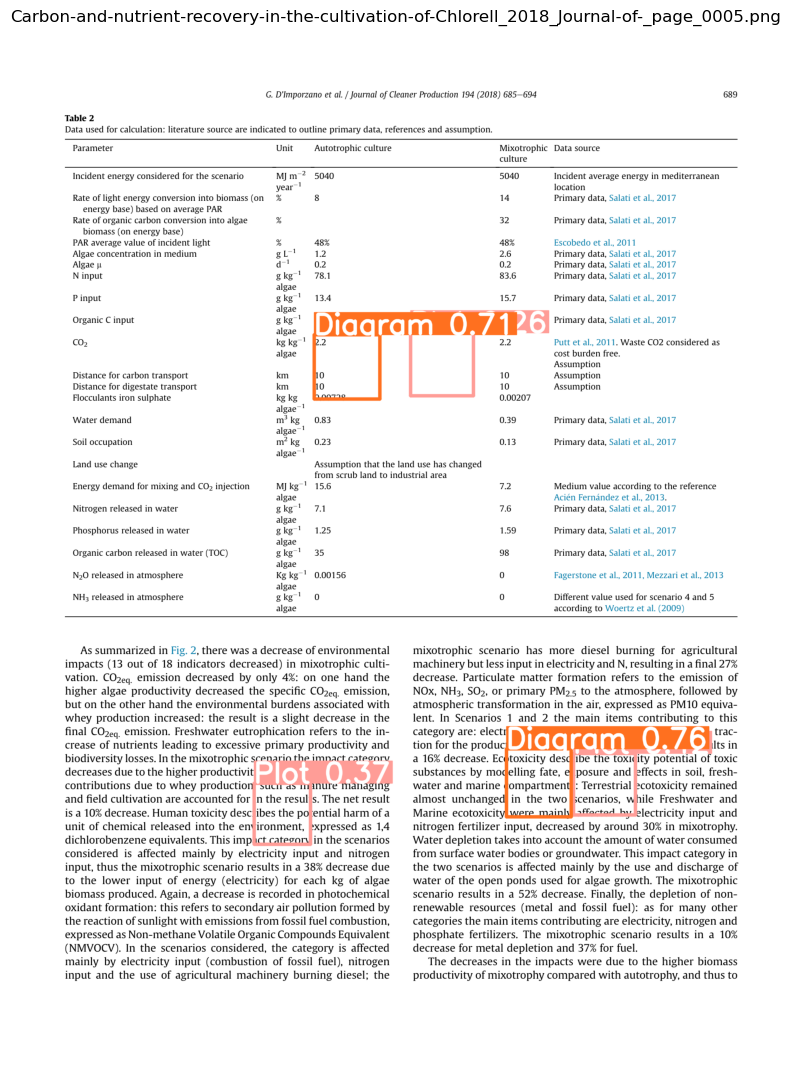

In [5]:
import random

val_images = sorted((YOLO_DATASET / "images" / "val").glob("*.png"))
if val_images:
    sample_img = random.choice(val_images)
    results = model.predict(str(sample_img), device=DEVICE)
    annotated = results[0].plot()  # BGR numpy array with boxes drawn

    import cv2
    plt.figure(figsize=(10, 10 * annotated.shape[0] / annotated.shape[1]))
    plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.title(sample_img.name)
    plt.show()
else:
    print("No val images found.")
